# Longtail Point: interannual high-water cycles

Lake Michigan-Huron synthetic scenario analysis, mirroring `low_water_cycles.ipynb`: loading checks, baseline distributions, event tables, five 200-year hydrographs, duration histograms, scenario tables, and event-rate response surfaces.

**Primary ordinary-event analysis:** whole parent spells with trailing 12-month mean **>=176.80 m**, lasting **>=24 months**, excluding entire spells with peak trailing mean **>177.30 m** or duration above a baseline-derived upper Tukey fence. No fixed five-year cap in this primary definition. This explicit notebook-only screen is **not** the standard library magnitude-band component.

Compare **>=24**, **>=36**, **24-60**, and **36-60 months**, each with three clearly separated methods: one-sided magnitude reference, standard bounded magnitude component, and whole-parent ordinary-event screen. The uncapped reference has neither an upper magnitude bound nor an upper duration bound for the first two definitions.

**Baseline `_0_0` is synthetic, not historical observations.** Historical 10-15-year cycling is a hypothesis, not a tuning target. Excluding extremes should reduce physical-event counts; a bounded magnitude band can instead increase component counts by splitting spells. We measure both, without equating them. Levels are interpreted as metres; datum, model provenance, historical representativeness, and ecological validity are not independently verified.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from climate_canvas.plots_utilities import plot_response_surface
from IPython.display import display
from matplotlib.colors import Normalize

from hydropattern.parsers import duration_parser, magnitude_parser
from hydropattern.patterns import Component, Result, evaluate_component, find_runs, moving_average
from hydropattern.scenario_grid import build_grid, parse_scenario_name
from hydropattern.scenarios import evaluate_scenarios
from hydropattern.timeseries import Timeseries, to_day_of_water_year

In [2]:
example = next(
    root / 'data' / 'avg'
    for root in (Path.cwd(), *Path.cwd().parents)
    if (root / 'data' / 'avg' / 'michiganhuron_avg.csv').is_file()
)
ts = Timeseries.from_csv(str(example / 'michiganhuron_avg.csv'), date_format='%Y-%m-%d')
scenario_names = list(ts.data.columns[:-1])
assert ts.data.index.is_unique and ts.data.index.is_monotonic_increasing
assert np.all(np.diff(ts.data.index.to_period('M').asi8) == 1)
assert np.isfinite(ts.data[scenario_names].to_numpy()).all()
assert ts.data.groupby(ts.data.index.year).size().eq(12).all()
baseline = ts.data['_0_0']
exposure_years = len(baseline) / 12
MEAN_MONTHS = 12
LOWER_M, UPPER_M = 176.80, 177.30
DURATIONS = {
    '>=2 years': ('ge24', ['>=', 24], 24, np.inf),
    '>=3 years': ('ge36', ['>=', 36], 36, np.inf),
    '2-5 years': ('24to60', [24, 60], 24, 60),
    '3-5 years': ('36to60', [36, 60], 36, 60),
}
mean12 = pd.Series(moving_average(baseline.to_numpy(), MEAN_MONTHS), index=baseline.index)
assert np.allclose(mean12, baseline.rolling(12, min_periods=12).mean(),
                   rtol=0, atol=1e-12, equal_nan=True)
assert mean12.iloc[:11].isna().all() and mean12.iloc[11:].notna().all()
print(f'{len(baseline):,} consecutive months; {exposure_years:,.0f} complete years; '
      f'{len(scenario_names)} scenarios; no missing levels.')
print(f'{baseline.index[0]:%Y-%m} through {baseline.index[-1]:%Y-%m}; synthetic baseline.')
display(ts.data[scenario_names].head())

12,360 consecutive months; 1,030 complete years; 17 scenarios; no missing levels.
1970-01 through 2999-12; synthetic baseline.


,_0_0,_0_1.5,_0_3,_0_5,_0_7,_5_1.5,_5_3,_5_5,_5_7,_10_3,_10_5,_10_7,_15_3,_15_5,_15_7,_20_5,_20_7
time,,,,,,,,,,,,,,,,,
1970-01-01,176.63,176.19,175.78,175.22,174.60,176.70,176.30,175.78,175.18,176.73,176.23,175.66,177.25,176.76,176.21,177.33,176.81
1970-02-01,176.63,176.19,175.78,175.24,174.61,176.71,176.32,175.80,175.21,176.75,176.25,175.68,177.26,176.78,176.24,177.36,176.85
1970-03-01,176.67,176.25,175.83,175.29,174.67,176.76,176.37,175.86,175.27,176.81,176.32,175.75,177.33,176.85,176.31,177.44,176.93
1970-04-01,176.76,176.34,175.92,175.38,174.76,176.87,176.46,175.95,175.37,176.92,176.42,175.86,177.44,176.96,176.42,177.57,177.07
1970-05-01,176.82,176.38,175.95,175.41,174.81,176.91,176.50,175.99,175.41,176.96,176.47,175.91,177.48,177.00,176.47,177.63,177.13


## Baseline calibration, not recurrence fitting

Baseline trailing-mean 75th percentile is **176.750 m**, 99th percentile **177.327 m**. Rounded to 0.10 m, these motivate **176.80 m** as a high-state threshold and **177.30 m** as an extreme-state edge. Rounding moves the lower threshold nearer the 80th percentile; sensitivity below includes 176.70, 176.75, 176.80, and 176.90 m. These are statistical conventions, not unique physical or ecological boundaries. Nothing is optimized toward 10-15 years.

Peak magnitude means the highest **trailing annual mean**, not the highest individual monthly level. Raw monthly peaks and complete-calendar-year ranges are also disclosed. Seasonal amplitude is diagnostic only; no hidden seasonality screen. A rare monthly state does not imply only 1% of multi-year spells reach it.

For duration extremes, calibrate **Q3 + 1.5 x IQR** from the durations of baseline one-sided spells lasting >=24 months. Freeze this fence and magnitude thresholds across scenarios. This upper fence excludes only the longest tail; **60 months** is a separate requested comparison, not a claim that every longer spell is statistically extreme.

Trailing smoothing removes seasonal oscillations and delays threshold crossings relative to a centred mean. First 11 means are unavailable. Standard duration conditions accept or reject an entire maximal qualifying run, never overlapping windows or subdivisions.

,Monthly level (m),Trailing 12-month mean (m),Annual monthly range (m)
Quantile,,,
0.01,175.82,175.8921,0.15
0.05,175.99,176.0428,0.20
0.25,176.28,176.2917,0.27
0.50,176.52,176.5175,0.32
0.75,176.76,176.7500,0.39
0.80,176.82,176.8017,0.41
0.95,177.08,177.0497,0.52
0.99,177.35,177.3267,0.60


Duration calibration: Q1=31.00, Q3=66.25, upper Tukey fence=119.125 months (9.93 years).


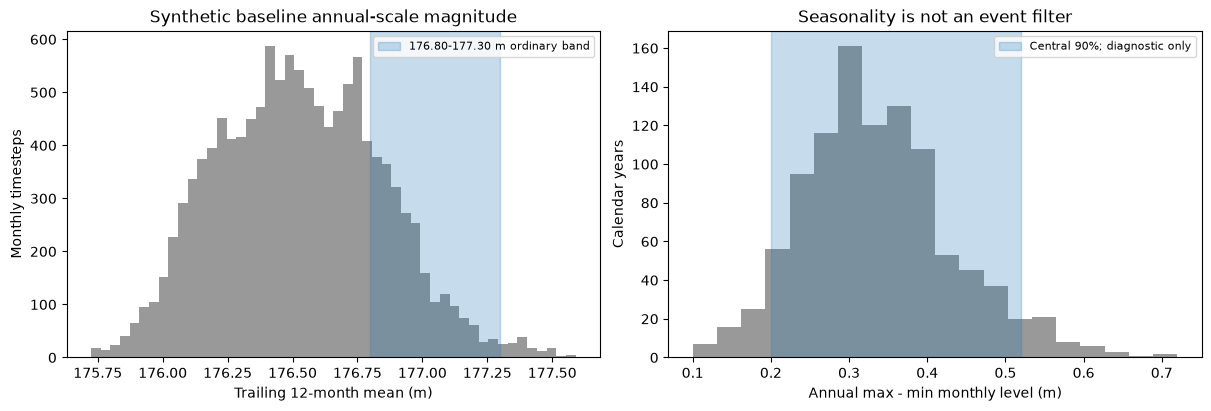

In [3]:
annual = baseline.groupby(baseline.index.year).agg(['mean', 'min', 'max'])
annual['range_m'] = (annual['max'] - annual['min']).round(2)
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.80, 0.95, 0.99]
display(pd.DataFrame({
    'Monthly level (m)': baseline.quantile(quantiles),
    'Trailing 12-month mean (m)': mean12.quantile(quantiles),
    'Annual monthly range (m)': annual['range_m'].quantile(quantiles),
}).rename_axis('Quantile').round(4))
parent_runs = find_runs(mean12.ge(LOWER_M).to_numpy(dtype=float))
parent_lengths = np.array([end - start + 1 for start, end in parent_runs])
multi_year_lengths = parent_lengths[parent_lengths >= 24]
q1, q3 = np.quantile(multi_year_lengths, [0.25, 0.75])
DURATION_FENCE_MONTHS = float(q3 + 1.5 * (q3 - q1))
print(f'Duration calibration: Q1={q1:.2f}, Q3={q3:.2f}, '
      f'upper Tukey fence={DURATION_FENCE_MONTHS:.3f} months '
      f'({DURATION_FENCE_MONTHS / 12:.2f} years).')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(mean12.dropna(), bins=50, color='0.6')
axes[0].axvspan(LOWER_M, UPPER_M, color='tab:blue', alpha=0.25,
               label='176.80-177.30 m ordinary band')
axes[0].set(xlabel='Trailing 12-month mean (m)', ylabel='Monthly timesteps',
            title='Synthetic baseline annual-scale magnitude')
axes[0].legend(fontsize=8)
season_low, season_high = annual['range_m'].quantile([0.05, 0.95])
axes[1].hist(annual['range_m'], bins=20, color='0.6')
axes[1].axvspan(season_low, season_high, color='tab:blue', alpha=0.25,
               label='Central 90%; diagnostic only')
axes[1].set(xlabel='Annual max - min monthly level (m)', ylabel='Calendar years',
            title='Seasonality is not an event filter')
axes[1].legend(fontsize=8)
plt.show()

## Explicit whole-parent screen

First evaluate a standard **one-sided** magnitude + duration component. Then reject its entire parent high spell if its peak trailing mean exceeds 177.30 m **or** its observed length exceeds the fixed duration fence. Rejection never leaves entry/exit fragments. Screened rates use `Result` count/rate bounds on a copied final outcome column; original library results stay unchanged. The copied diagnostic characteristic columns still describe the unscreened component, so these copies are used only for final event counts, tables, and plots, not characteristic summaries.

If a non-rejected parent adjoins unavailable smoothed values, its peak/length may depend on the unknown part: potentially successful outcomes become unknown rather than claiming exact classification. Definite failures stay failures. No extrapolation beyond the observed record. Count bounds are conservative independent-outcome bounds, not confidence intervals.

Whole-parent screening is additional analysis explicitly approved for this notebook, not a change to library component semantics. Standard bounded-band results remain visible for direct comparison with the low-water notebook.

In [4]:
def high_component(name, lower, upper, duration_metrics):
    magnitude_metrics = ['>=', lower, MEAN_MONTHS] if upper is None else [lower, upper, MEAN_MONTHS]
    return Component(name=name, characteristics=[
        magnitude_parser(metrics=magnitude_metrics, order=1),
        duration_parser(metrics=duration_metrics, order=2),
    ], is_success_pattern=True)


def screen_parent_extremes(result, smoothed, lower, upper, duration_fence):
    frame = result.df.copy()
    outcomes = frame[result.component.name].to_numpy(copy=True)
    for start, end in find_runs(smoothed.ge(lower).to_numpy(dtype=float)):
        if smoothed.iloc[start:end + 1].max() > upper or end - start + 1 > duration_fence:
            outcomes[start:end + 1] = 0
            continue
        unknown_boundary = ((start > 0 and pd.isna(smoothed.iloc[start - 1]))
                            or (end + 1 < len(smoothed) and pd.isna(smoothed.iloc[end + 1])))
        if unknown_boundary:
            section = outcomes[start:end + 1]
            section[section != 0] = np.nan
    frame[result.component.name] = outcomes
    return replace(result, df=frame)


def event_summary(result):
    runs = find_runs(result.df[result.component.name].to_numpy())
    lengths = np.array([end - start + 1 for start, end in runs])
    starts = np.array([start for start, end in runs])
    ends = np.array([end for start, end in runs])
    gaps = (starts[1:] - ends[:-1] - 1) / 12
    spacing = np.diff(starts) / 12
    counts, rates = result.event_count_bounds(), result.event_rate_bounds()
    exact = counts.lower == counts.upper and rates.lower == rates.upper
    return {
        'Exposure (years)': len(result.df) / 12,
        'Event count lower': counts.lower, 'Event count upper': counts.upper,
        'Events per 100 years lower': rates.lower * 100,
        'Events per 100 years upper': rates.upper * 100,
        'Events per 100 years': rates.lower * 100 if exact else np.nan,
        'Plotted rate basis': 'Exact' if exact else 'Ambiguous; not plotted',
        'Unknown outcome timesteps': int(result.df[result.component.name].isna().sum()),
        'Known-success runs': len(runs),
        'Median months (known runs)': np.median(lengths) if len(lengths) else np.nan,
        'Min months (known runs)': lengths.min() if len(lengths) else np.nan,
        'Max months (known runs)': lengths.max() if len(lengths) else np.nan,
        'Mean end-to-next-start gap (years)': gaps.mean() if len(gaps) else np.nan,
        'Median end-to-next-start gap (years)': np.median(gaps) if len(gaps) else np.nan,
        'Mean start-to-start spacing (years)': spacing.mean() if len(spacing) else np.nan,
        'Exposure / exact count (years)': len(result.df) / 12 / counts.lower
            if exact and counts.lower > 0 else np.nan,
    }

In [5]:
test_component = Component('test_high', [], True)
test_means = pd.Series([0., 2., 2., 4., 2., 2., 0., 2., 2., 0.])
test_frame = pd.DataFrame({'level': test_means, 'test_high': test_means.ge(1).astype(float)})
test_result = Result(test_frame, test_component)
screened = screen_parent_extremes(test_result, test_means, 1, 3, np.inf)
assert find_runs(screened.df['test_high'].to_numpy()) == [(7, 8)]
assert find_runs(test_result.df['test_high'].to_numpy()) == [(1, 5), (7, 8)]
assert find_runs(test_means.between(1, 3).to_numpy(dtype=float)) == [(1, 2), (4, 5), (7, 8)]
assert find_runs(screen_parent_extremes(test_result, test_means, 1, 4, 5).df['test_high'].to_numpy()) == [(1, 5), (7, 8)]
assert find_runs(screen_parent_extremes(test_result, test_means, 1, 4, 4).df['test_high'].to_numpy()) == [(7, 8)]
unknown_means = pd.Series([np.nan, 2., 2., 0.])
unknown_frame = pd.DataFrame({'level': unknown_means, 'test_high': [np.nan, 1., 1., 0.]})
unknown_screen = screen_parent_extremes(Result(unknown_frame, test_component), unknown_means, 1, 3, 5)
assert unknown_screen.df['test_high'].iloc[:3].isna().all()
assert unknown_screen.df['test_high'].iloc[3] == 0
for length in [23, 24, 35, 36, 60, 61]:
    values = np.r_[np.zeros(12), np.ones(length), np.zeros(12)]
    frame = pd.DataFrame({'level': values}, index=pd.date_range('1970-01-01', periods=len(values), freq='MS'))
    frame['dowy'] = frame.index.map(to_day_of_water_year)
    for label, (suffix, metrics, minimum, maximum) in DURATIONS.items():
        component = Component('test_duration', [
            magnitude_parser(metrics=['>=', 1, 1], order=1),
            duration_parser(metrics=metrics, order=2),
        ], True)
        result = evaluate_component(frame, component)
        assert result.event_count() == int(minimum <= length <= maximum)
        if not minimum <= length <= maximum:
            assert event_summary(result)['Events per 100 years'] == 0
print('Checks: whole-spell rejection, no mutation, no fragments, inclusive limits, unknown boundaries, '
      'all four duration definitions at boundary lengths, and true zero rates.')

Checks: whole-spell rejection, no mutation, no fragments, inclusive limits, unknown boundaries, all four duration definitions at boundary lengths, and true zero rates.


,Lower (m),Upper (m),Method,Duration,Event count lower,Event count upper,Events per 100 years lower,Events per 100 years upper,Median months (known runs),Exposure / exact count (years)
0,176.70,inf,One-sided reference,>=2 years,51,51,4.951,4.951,58.0,20.196
1,176.70,177.1,Standard band,>=2 years,55,55,5.340,5.340,44.0,18.727
2,176.70,177.1,Whole-parent screen,>=2 years,34,34,3.301,3.301,45.0,30.294
3,176.70,177.2,Standard band,>=2 years,55,55,5.340,5.340,50.0,18.727
4,176.70,177.2,Whole-parent screen,>=2 years,41,41,3.981,3.981,50.0,25.122
5,176.70,177.3,Standard band,>=2 years,57,57,5.534,5.534,50.0,18.070
6,176.70,177.3,Whole-parent screen,>=2 years,44,44,4.272,4.272,52.0,23.409
7,176.70,177.4,Standard band,>=2 years,54,54,5.243,5.243,55.0,19.074
8,176.70,177.4,Whole-parent screen,>=2 years,45,45,4.369,4.369,52.0,22.889
9,176.70,inf,One-sided reference,>=3 years,45,45,4.369,4.369,66.0,22.889


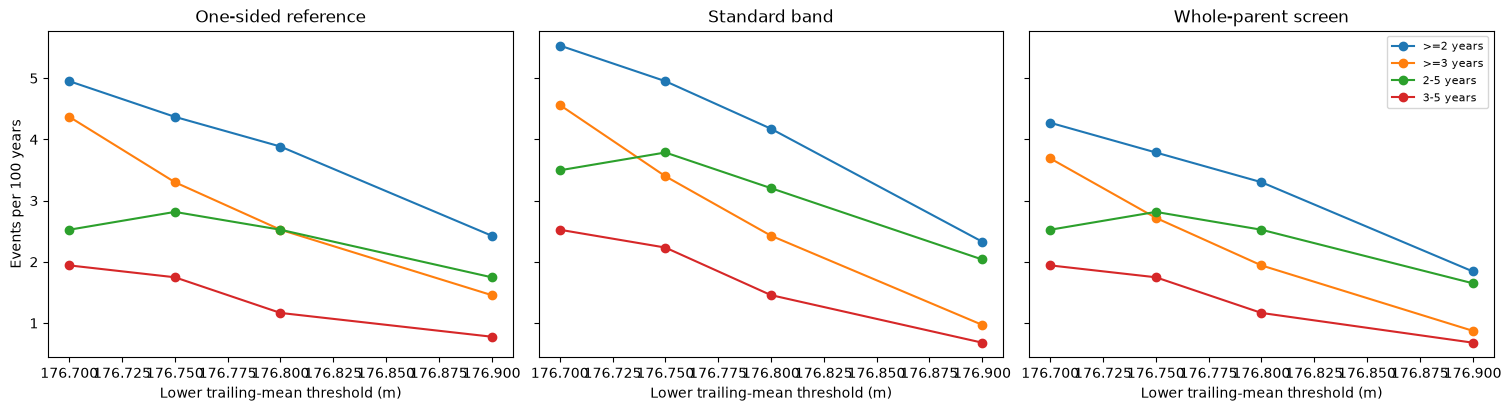

In [6]:
baseline_frame = ts.data[['_0_0', 'dowy']]
sensitivity_rows = []
for lower in [176.70, 176.75, 176.80, 176.90]:
    for label, (suffix, metrics, minimum, maximum) in DURATIONS.items():
        reference = evaluate_component(baseline_frame, high_component('reference', lower, None, metrics))
        sensitivity_rows.append({'Lower (m)': lower, 'Upper (m)': np.inf,
                                 'Method': 'One-sided reference', 'Duration': label,
                                 **event_summary(reference)})
        for upper in [177.10, 177.20, 177.30, 177.40]:
            band = evaluate_component(baseline_frame, high_component('band', lower, upper, metrics))
            whole = screen_parent_extremes(reference, mean12, lower, upper, DURATION_FENCE_MONTHS)
            for method, result in [('Standard band', band), ('Whole-parent screen', whole)]:
                sensitivity_rows.append({'Lower (m)': lower, 'Upper (m)': upper,
                                         'Method': method, 'Duration': label,
                                         **event_summary(result)})
sensitivity = pd.DataFrame(sensitivity_rows)
with pd.option_context('display.max_rows', None):
    display(sensitivity[['Lower (m)', 'Upper (m)', 'Method', 'Duration',
                         'Event count lower', 'Event count upper',
                         'Events per 100 years lower', 'Events per 100 years upper',
                         'Median months (known runs)', 'Exposure / exact count (years)']].round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
for ax, method in zip(axes, ['One-sided reference', 'Standard band', 'Whole-parent screen']):
    selected = sensitivity[(sensitivity['Method'] == method)
                           & ((sensitivity['Upper (m)'] == UPPER_M)
                              | np.isinf(sensitivity['Upper (m)']))]
    for label in DURATIONS:
        subset = selected[selected['Duration'] == label]
        ax.plot(subset['Lower (m)'], subset['Events per 100 years'], marker='o', label=label)
    ax.set(title=method, xlabel='Lower trailing-mean threshold (m)')
axes[0].set_ylabel('Events per 100 years')
axes[-1].legend(fontsize=8)
plt.show()

In [7]:
components = []
for label, (suffix, metrics, minimum, maximum) in DURATIONS.items():
    components.append(high_component(f'high_reference_{suffix}', LOWER_M, None, metrics))
    components.append(high_component(f'high_band_{suffix}', LOWER_M, UPPER_M, metrics))
scenario_results = evaluate_scenarios(ts, components)
results_by_definition = {}
for label, (suffix, metrics, minimum, maximum) in DURATIONS.items():
    reference_results = scenario_results.by_component(f'high_reference_{suffix}')
    results_by_definition[('One-sided reference', label)] = reference_results
    results_by_definition[('Standard band', label)] = scenario_results.by_component(f'high_band_{suffix}')
    results_by_definition[('Whole-parent screen', label)] = {
        name: screen_parent_extremes(
            result,
            pd.Series(moving_average(ts.data[name].to_numpy(), MEAN_MONTHS), index=ts.data.index),
            LOWER_M, UPPER_M, DURATION_FENCE_MONTHS,
        ) for name, result in reference_results.items()
    }
baseline_comparison = pd.DataFrame([
    {'Method': method, 'Duration': label, **event_summary(results['_0_0'])}
    for (method, label), results in results_by_definition.items()
]).set_index(['Method', 'Duration'])
display(baseline_comparison.round(3))
for label in DURATIONS:
    ordinary = baseline_comparison.loc[('Whole-parent screen', label), 'Event count lower']
    reference = baseline_comparison.loc[('One-sided reference', label), 'Event count lower']
    assert ordinary <= reference
assert np.isclose(DURATION_FENCE_MONTHS, 119.125)
for method, expected in [('One-sided reference', [40, 26, 26, 12]),
                         ('Standard band', [43, 25, 33, 15]),
                         ('Whole-parent screen', [34, 20, 26, 12])]:
    for label, count in zip(DURATIONS, expected):
        result = results_by_definition[(method, label)]['_0_0']
        assert result.event_count() == count
        assert np.isclose(result.event_rate() * 100, count / exposure_years * 100)

,,Exposure (years),Event count lower,Event count upper,Events per 100 years lower,Events per 100 years upper,Events per 100 years,Plotted rate basis,Unknown outcome timesteps,Known-success runs,Median months (known runs),Min months (known runs),Max months (known runs),Mean end-to-next-start gap (years),Median end-to-next-start gap (years),Mean start-to-start spacing (years),Exposure / exact count (years)
Method,Duration,,,,,,,,,,,,,,,,
One-sided reference,>=2 years,1030.0,40,40,3.883,3.883,3.883,Exact,0,40,44.5,24,148,19.293,15.500,23.821,25.750
Standard band,>=2 years,1030.0,43,43,4.175,4.175,4.175,Exact,0,43,41.0,24,100,18.341,14.667,22.119,23.953
Whole-parent screen,>=2 years,1030.0,34,34,3.301,3.301,3.301,Exact,0,34,40.5,24,81,24.429,16.250,28.152,30.294
One-sided reference,>=3 years,1030.0,26,26,2.524,2.524,2.524,Exact,0,26,61.5,36,148,30.753,24.667,36.147,39.615
Standard band,>=3 years,1030.0,25,25,2.427,2.427,2.427,Exact,0,25,54.0,36,100,33.215,27.708,37.854,41.200
Whole-parent screen,>=3 years,1030.0,20,20,1.942,1.942,1.942,Exact,0,20,55.5,36,81,42.531,41.500,47.092,51.500
One-sided reference,2-5 years,1030.0,26,26,2.524,2.524,2.524,Exact,0,26,33.5,24,59,34.063,15.500,37.160,39.615
Standard band,2-5 years,1030.0,33,33,3.204,3.204,3.204,Exact,0,33,35.0,24,59,25.924,16.375,29.031,31.212
Whole-parent screen,2-5 years,1030.0,26,26,2.524,2.524,2.524,Exact,0,26,33.5,24,59,34.063,15.500,37.160,39.615


## What the baseline supports

Full record: **1,030 years**. At >=176.80 m, >=24 months with no upper magnitude/duration bounds gives **40 spells (3.883/100 years)**. Whole-parent ordinary screening retains **34 (3.301/100 years)**; median length **40.5 months**. Exposure/count is **30.3 years**, mean start-to-start spacing **28.2 years**, mean end-to-next-start gap **24.4 years**. These are different descriptive measures, none proves periodicity.

The duration fence is **119.125 months**. Six >=24-month parents exceed the peak edge; two exceed the duration fence, both already among those six. Reject their union once. A fixed five-year ceiling rejects substantially more spells and is not interchangeable with an extreme-tail screen.

| Duration | Uncapped-magnitude reference count | Standard band count | Whole-parent ordinary count | Ordinary events/100 years |
| --- | ---: | ---: | ---: | ---: |
| >=24 months | 40 | 43 | 34 | 3.301 |
| >=36 months | 26 | 25 | 20 | 1.942 |
| 24-60 months | 26 | 33 | 26 | 2.524 |
| 36-60 months | 12 | 15 | 12 | 1.165 |

A 176.80-177.30 m band **increases** the >=24-month count from 40 to 43 and the 24-60-month count from 26 to 33 through fragmentation. Those are valid standard component events, not evidence of more distinct physical cycles. Whole-parent screening avoids this artifact.

This particular synthetic threshold-based analysis does **not establish** the historical 10-15-year hypothesis, even before screening. Threshold sensitivity is shown rather than choosing a definition to force that interval. Below-threshold oscillations, other cycle definitions, and validation against historical data remain outside this analysis.

In [8]:
parent_rows = []
for parent_id, (start, end) in enumerate(parent_runs, 1):
    raw = baseline.iloc[start:end + 1]
    year_counts = raw.groupby(raw.index.year).size()
    amplitudes = annual.loc[year_counts.index[year_counts.eq(12)], 'range_m']
    peak = mean12.iloc[start:end + 1].max()
    months = end - start + 1
    parent_rows.append({
        'Parent': parent_id, 'Start index': start, 'End index': end,
        'Start': baseline.index[start].strftime('%Y-%m'),
        'End': baseline.index[end].strftime('%Y-%m'), 'Months': months,
        'Peak 12-month mean (m)': peak, 'Raw monthly peak (m)': raw.max(),
        'Within-spell monthly range (m)': raw.max() - raw.min(),
        'Complete years': len(amplitudes), 'Median annual range (m)': amplitudes.median(),
        'Peak extreme': peak > UPPER_M, 'Duration extreme': months > DURATION_FENCE_MONTHS,
        'Ordinary >=24 months': months >= 24 and peak <= UPPER_M and months <= DURATION_FENCE_MONTHS,
    })
parents = pd.DataFrame(parent_rows).set_index('Parent')
multi_parents = parents[parents['Months'] >= 24]
display(multi_parents.drop(columns=['Start index', 'End index']).round(3))
peak_extreme = multi_parents['Peak extreme']
duration_extreme = multi_parents['Duration extreme']
print(f'{peak_extreme.sum()} peak extremes; {duration_extreme.sum()} duration extremes; '
      f'{(peak_extreme & duration_extreme).sum()} overlap; '
      f'{(peak_extreme | duration_extreme).sum()} distinct parents rejected.')
assert multi_parents['Ordinary >=24 months'].sum() == 34
ordinary_parents = multi_parents[multi_parents['Ordinary >=24 months']]
display(ordinary_parents[['Months', 'Peak 12-month mean (m)', 'Raw monthly peak (m)',
                          'Median annual range (m)']].describe().round(3))
fragment_rows = []
for label in DURATIONS:
    band_result = results_by_definition[('Standard band', label)]['_0_0']
    for start, end in find_runs(band_result.df[band_result.component.name].to_numpy()):
        parent_id = parents.index[(parents['Start index'] <= start) & (parents['End index'] >= end)][0]
        parent = parents.loc[parent_id]
        fragment_rows.append({'Duration': label, 'Parent': parent_id,
                              'Start': baseline.index[start].strftime('%Y-%m'),
                              'End': baseline.index[end].strftime('%Y-%m'),
                              'Band months': end - start + 1, 'Parent months': parent['Months'],
                              'Fragment': start != parent['Start index'] or end != parent['End index']})
fragments = pd.DataFrame(fragment_rows)
display(fragments[fragments['Fragment']])
display(fragments.groupby('Duration', sort=False).agg(
    Band_events=('Parent', 'size'), Distinct_parents=('Parent', 'nunique'),
    Fragment_events=('Fragment', 'sum'),
))

,Start,End,Months,Peak 12-month mean (m),Raw monthly peak (m),Within-spell monthly range (m),Complete years,Median annual range (m),Peak extreme,Duration extreme,Ordinary >=24 months
Parent,,,,,,,,,,,
1,1995-08,1999-04,45,177.077,177.24,0.68,3,0.330,False,False,True
4,2014-11,2017-10,36,177.074,177.23,0.53,2,0.450,False,False,True
5,2022-02,2026-12,59,177.000,177.08,0.48,4,0.270,False,False,True
6,2044-04,2046-03,24,176.883,177.02,0.50,1,0.360,False,False,True
7,2051-09,2056-02,54,177.289,177.44,0.89,4,0.400,False,False,True
9,2078-01,2080-07,31,176.867,177.01,0.40,2,0.355,False,False,True
12,2098-10,2104-03,66,177.195,177.36,0.78,5,0.340,False,False,True
15,2180-09,2186-08,72,177.155,177.25,0.63,5,0.320,False,False,True
20,2221-02,2223-03,26,176.923,176.99,0.35,1,0.300,False,False,True


6 peak extremes; 2 duration extremes; 2 overlap; 6 distinct parents rejected.


,Months,Peak 12-month mean (m),Raw monthly peak (m),Median annual range (m)
count,34.000,34.000,34.000,34.000
mean,44.059,177.027,177.171,0.329
std,16.620,0.116,0.122,0.059
min,24.000,176.847,176.970,0.225
25%,30.250,176.954,177.080,0.292
50%,40.500,177.002,177.150,0.320
75%,58.500,177.114,177.248,0.355
max,81.000,177.289,177.440,0.480


,Duration,Parent,Start,End,Band months,Parent months,Fragment
13,>=2 years,28,2275-05,2278-09,41,94,True
18,>=2 years,36,2390-01,2392-08,32,104,True
19,>=2 years,36,2394-04,2396-03,24,104,True
24,>=2 years,42,2499-09,2504-02,54,97,True
28,>=2 years,48,2587-10,2591-05,44,78,True
31,>=2 years,55,2733-06,2741-09,100,148,True
32,>=2 years,55,2742-11,2745-09,35,148,True
40,>=2 years,68,2899-04,2902-01,34,124,True
41,>=2 years,68,2904-02,2909-07,66,124,True
51,>=3 years,28,2275-05,2278-09,41,94,True


,Band_events,Distinct_parents,Fragment_events
Duration,,,
>=2 years,43,40,9
>=3 years,25,25,5
2-5 years,33,32,7
3-5 years,15,15,3


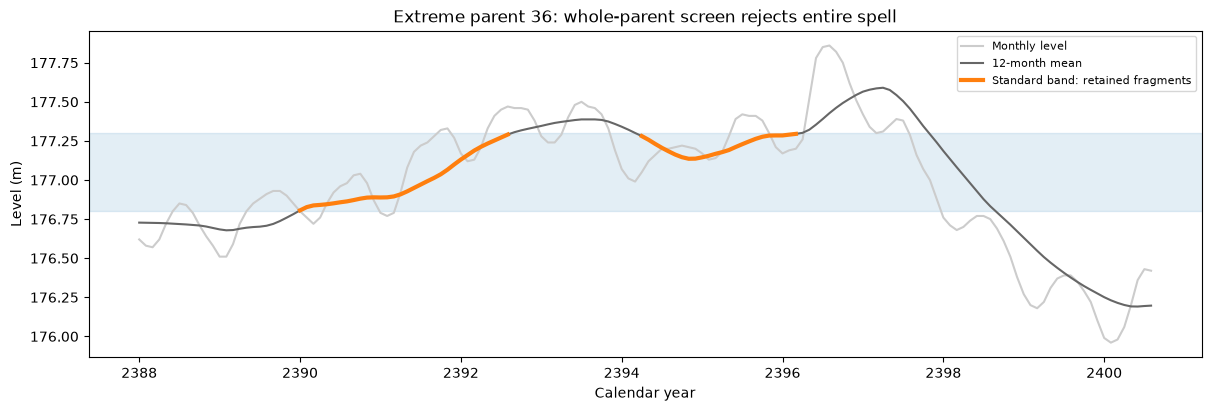

In [9]:
extreme_parent = multi_parents['Peak 12-month mean (m)'].idxmax()
parent = parents.loc[extreme_parent]
first = max(0, int(parent['Start index']) - 24)
last = min(len(baseline), int(parent['End index']) + 25)
calendar_years = baseline.index.year + (baseline.index.month - 1) / 12
band_result = results_by_definition[('Standard band', '>=2 years')]['_0_0']
ordinary_result = results_by_definition[('Whole-parent screen', '>=2 years')]['_0_0']
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(calendar_years[first:last], baseline.iloc[first:last], color='0.8', label='Monthly level')
ax.plot(calendar_years[first:last], mean12.iloc[first:last], color='0.4', label='12-month mean')
band_means = mean12.where(band_result.df[band_result.component.name].eq(1))
ax.plot(calendar_years[first:last], band_means.iloc[first:last], color='tab:orange', linewidth=3,
        label='Standard band: retained fragments')
ax.axhspan(LOWER_M, UPPER_M, color='tab:blue', alpha=0.12)
ax.set(xlabel='Calendar year', ylabel='Level (m)',
       title=f'Extreme parent {extreme_parent}: whole-parent screen rejects entire spell')
ax.ticklabel_format(axis='x', useOffset=False)
ax.legend(fontsize=8)
plt.show()
assert ordinary_result.df[ordinary_result.component.name].iloc[
    int(parent['Start index']):int(parent['End index']) + 1
].eq(0).all()

In [10]:
PLOT_LOWER_M = 176.75
plot_component = high_component('high_water_plot_ge24', PLOT_LOWER_M, None, ['>=', 24])
plot_results = evaluate_scenarios(ts, [plot_component]).by_component(plot_component.name)
plot_baseline_result = plot_results['_0_0']
plot_rows = []
for name, result in plot_results.items():
    coordinates = parse_scenario_name(name)
    if coordinates is None:
        raise ValueError(f'Invalid scenario-grid name: {name}')
    summary = event_summary(result)
    if summary['Plotted rate basis'] != 'Exact':
        summary['Events per 100 years'] = (
            summary['Events per 100 years lower'] + summary['Events per 100 years upper']
        ) / 2
        summary['Plotted rate basis'] = 'Midpoint of bounds (user-selected)'
    plot_rows.append({'Scenario': name, 'Precipitation delta (%)': coordinates[0],
                      'Temperature delta (deg C)': coordinates[1], **summary})
plot_rates = pd.DataFrame(plot_rows).set_index('Scenario')
baseline_plot_rate = float(plot_rates.loc['_0_0', 'Events per 100 years'])
plot_grid_axes = build_grid(list(plot_results), plot_rates['Events per 100 years'].to_dict())
assert plot_rates['Events per 100 years'].notna().all()
assert np.allclose(plot_rates['Events per 100 years'],
                   (plot_rates['Events per 100 years lower']
                    + plot_rates['Events per 100 years upper']) / 2)
assert np.isclose(baseline_plot_rate, plot_baseline_result.event_rate() * 100)
print(f'Plot definition: >= {PLOT_LOWER_M:.2f} m trailing 12-month mean; >=24 months; '
      'no upper bounds or whole-parent screen.')
print(f'Baseline: {plot_baseline_result.event_count()} events; '
      f'{baseline_plot_rate:.6f} events per 100 years.')

Plot definition: >= 176.75 m trailing 12-month mean; >=24 months; no upper bounds or whole-parent screen.
Baseline: 45 events; 4.368932 events per 100 years.


## Event tables and full-record plots

**Rate = 100 x distinct final-success run count / observed years**, including unknown-outcome months in exposure. Zero events is a valid zero. The table below lists ordinary whole parents for the primary >=24-month definition. Complete-year monthly ranges describe seasonal variability within spells; years without all 12 spell months do not supply an annual-range statistic.

End-to-next-start gaps count intervening non-event months: `(next_start - previous_end - 1) / 12`. Start-to-start spacing includes the preceding event. Exposure/count also includes record-edge exposure. Mean gaps do not establish periodicity. When bounds differ, known-run lengths/gaps describe only definite-success runs, not a complete physical-event catalogue.

Hydrograph shows first **1,000 years (1970-2969)** in five stacked 200-year panels, common level scale, using the requested **>=176.75 m trailing 12-month mean for >=24 months**, without upper bounds or extreme screening. Earlier ordinary-event tables and histograms retain their separate 176.80 m screened definition. All rates use **1,030 years**.

,Start,End,Months,Peak 12-month mean (m),Raw monthly peak (m),Within-spell monthly range (m),Complete years,Median annual range (m),Peak extreme,Duration extreme,Ordinary >=24 months,Gap to next start (years)
Parent,,,,,,,,,,,,
1,1995-08,1999-04,45,177.077,177.24,0.68,3,0.330,False,False,True,15.500
4,2014-11,2017-10,36,177.074,177.23,0.53,2,0.450,False,False,True,4.250
5,2022-02,2026-12,59,177.000,177.08,0.48,4,0.270,False,False,True,17.250
6,2044-04,2046-03,24,176.883,177.02,0.50,1,0.360,False,False,True,5.417
7,2051-09,2056-02,54,177.289,177.44,0.89,4,0.400,False,False,True,21.833
9,2078-01,2080-07,31,176.867,177.01,0.40,2,0.355,False,False,True,18.167
12,2098-10,2104-03,66,177.195,177.36,0.78,5,0.340,False,False,True,76.417
15,2180-09,2186-08,72,177.155,177.25,0.63,5,0.320,False,False,True,34.417
20,2221-02,2223-03,26,176.923,176.99,0.35,1,0.300,False,False,True,1.333


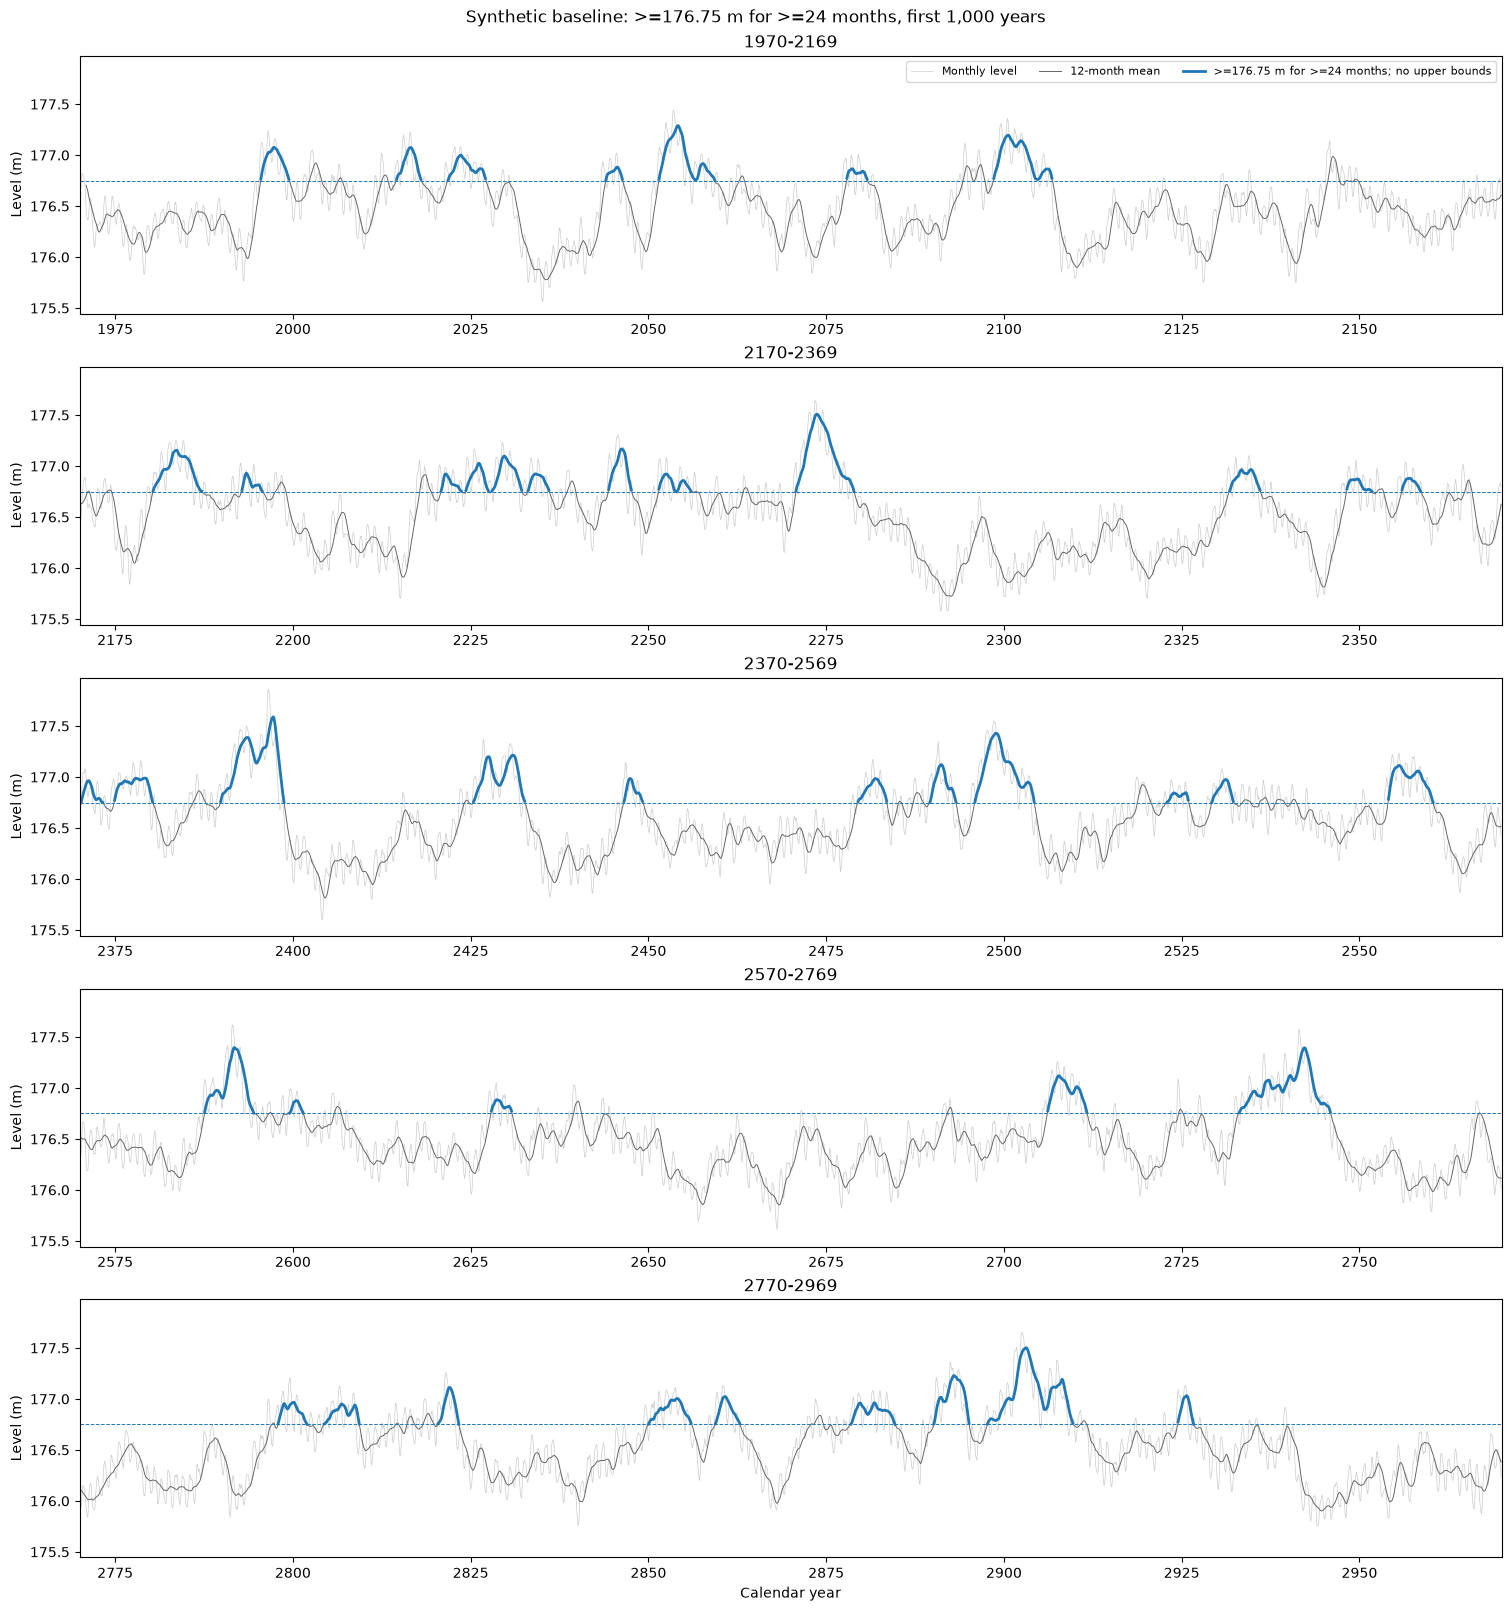

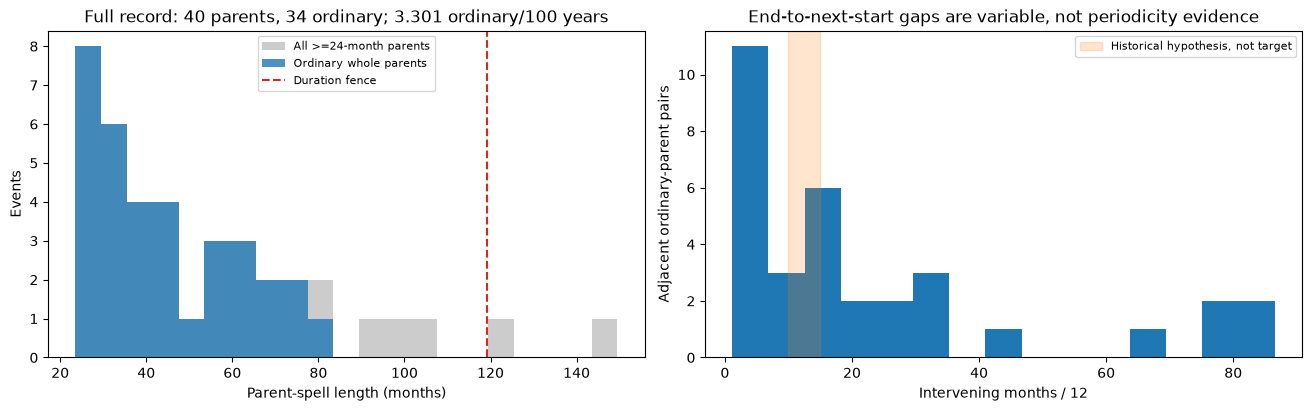

In [11]:
baseline_events = ordinary_parents.drop(columns=['Start index', 'End index']).copy()
baseline_events['Gap to next start (years)'] = (
    ordinary_parents['Start index'].shift(-1) - ordinary_parents['End index'] - 1
) / 12
display(baseline_events.round(3))
assert len(baseline_events) == ordinary_result.event_count()
assert baseline_events['Months'].between(24, DURATION_FENCE_MONTHS).all()
assert baseline_events['Peak 12-month mean (m)'].le(UPPER_M).all()
assert find_runs(ordinary_result.df[ordinary_result.component.name].to_numpy()) == list(
    ordinary_parents[['Start index', 'End index']].itertuples(index=False, name=None)
)
panel_months = 200 * 12
assert len(baseline) >= 5 * panel_months
event_means = mean12.where(plot_baseline_result.df[plot_component.name].eq(1))
fig, axes = plt.subplots(5, 1, figsize=(15, 16), sharey=True, constrained_layout=True)
for panel, ax in enumerate(axes):
    first, last = panel * panel_months, (panel + 1) * panel_months
    years = calendar_years[first:last]
    ax.plot(years, baseline.iloc[first:last], color='0.8', linewidth=0.5, label='Monthly level')
    ax.plot(years, mean12.iloc[first:last], color='0.4', linewidth=0.7, label='12-month mean')
    ax.plot(years, event_means.iloc[first:last], color='tab:blue', linewidth=2,
            label='>=176.75 m for >=24 months; no upper bounds')
    ax.axhline(PLOT_LOWER_M, color='tab:blue', linestyle='--', linewidth=0.7)
    start_year = int(baseline.index[first].year)
    ax.set(xlim=(start_year, start_year + 200), ylabel='Level (m)',
           title=f'{start_year}-{start_year + 199}')
    ax.ticklabel_format(axis='x', useOffset=False)
axes[0].legend(fontsize=8, ncols=3)
axes[-1].set_xlabel('Calendar year')
fig.suptitle('Synthetic baseline: >=176.75 m for >=24 months, first 1,000 years')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
bins = np.arange(23.5, multi_parents['Months'].max() + 6, 6)
axes[0].hist(multi_parents['Months'], bins=bins, color='0.8', label='All >=24-month parents')
axes[0].hist(baseline_events['Months'], bins=bins, color='tab:blue', alpha=0.8,
             label='Ordinary whole parents')
axes[0].axvline(DURATION_FENCE_MONTHS, color='tab:red', linestyle='--', label='Duration fence')
axes[0].set(xlabel='Parent-spell length (months)', ylabel='Events',
            title='Full record: 40 parents, 34 ordinary; 3.301 ordinary/100 years')
axes[0].legend(fontsize=8)
gaps = baseline_events['Gap to next start (years)'].dropna()
axes[1].hist(gaps, bins=15, color='tab:blue')
axes[1].axvspan(10, 15, color='tab:orange', alpha=0.2, label='Historical hypothesis, not target')
axes[1].set(xlabel='Intervening months / 12', ylabel='Adjacent ordinary-parent pairs',
            title='End-to-next-start gaps are variable, not periodicity evidence')
axes[1].legend(fontsize=8)
plt.show()

## Scenario event rates and uncertainty

Apply the same baseline-calibrated thresholds and duration fence to all 17 scenarios. Tables preserve all four duration definitions and all three methods. Use `Result.event_count_bounds()` and `Result.event_rate_bounds()`; equal bounds identify exact rates. Unknown timestep counts remain visible even where event counts are exact. Summary portion-of-known-outcomes metrics are **not** used.

The requested plot definition is **>=176.75 m trailing 12-month mean for >=24 months**, without upper bounds or the ordinary-event screen. Its separate scenario table supplies **midpoints of computed rate bounds for every ambiguous scenario**, explicitly user-selected; no low-water midpoint is reused. Earlier four-duration analysis tables preserve their original exact/ambiguous values. Missing scenario combinations remain NaN. Exact zero is supplied as zero.

Show both **`interpolate=False, fillin=False`** and **`interpolate=True, fillin=True`** for the requested definition, with default **RdBu** color map and identical normalization/levels/ticks. Color limits are symmetric around its baseline rate, so **baseline is white at the numerical and visual midpoint of the color bar**. Symmetric limits may extend below zero solely for color balance; event rates remain nonnegative. Precipitation delta is horizontal; temperature delta vertical. No minimum-coverage subtitle or filter.

Midpoints are descriptive representatives, not exact counts or expected-value estimates. Bounds and unknown timesteps remain in the plot table. Outlined supplied cells include midpoints, so outlines do not guarantee exact rates. Interpolation/filling estimates absent scenario combinations; it does not resolve event-count uncertainty.

In [12]:
scenario_rows = []
for (method, label), results in results_by_definition.items():
    for name, result in results.items():
        coordinates = parse_scenario_name(name)
        if coordinates is None:
            raise ValueError(f'Invalid scenario-grid name: {name}')
        precipitation_delta, temperature_delta = coordinates
        scenario_rows.append({'Method': method, 'Duration': label, 'Scenario': name,
                              'Precipitation delta (%)': precipitation_delta,
                              'Temperature delta (deg C)': temperature_delta,
                              **event_summary(result)})
scenario_rates = pd.DataFrame(scenario_rows).set_index(['Method', 'Duration', 'Scenario'])
rate_columns = ['Precipitation delta (%)', 'Temperature delta (deg C)', 'Exposure (years)',
                'Event count lower', 'Event count upper', 'Events per 100 years lower',
                'Events per 100 years upper', 'Events per 100 years',
                'Plotted rate basis', 'Unknown outcome timesteps']
for method in ['One-sided reference', 'Standard band', 'Whole-parent screen']:
    print(method)
    with pd.option_context('display.max_rows', None):
        display(scenario_rates.xs(method, level='Method')[rate_columns].round(3))
ambiguous_rates = scenario_rates[scenario_rates['Events per 100 years'].isna()]
print(f'{len(ambiguous_rates)} evaluated method/duration/scenario rates ambiguous; left blank.')
display(ambiguous_rates[rate_columns].round(3))
assert len(scenario_rates) == 3 * 4 * len(scenario_names)
assert scenario_rates['Exposure (years)'].eq(exposure_years).all()
assert scenario_rates['Events per 100 years lower'].le(
    scenario_rates['Events per 100 years upper']).all()
assert scenario_rates.loc[('Whole-parent screen', '>=2 years', '_0_0'), 'Event count lower'] == 34
surface_grids = {}
for key, results in results_by_definition.items():
    table = scenario_rates.xs(key, level=['Method', 'Duration'])
    surface_grids[key] = build_grid(list(results), table['Events per 100 years'].to_dict())
precipitation_deltas, temperature_deltas, ordinary_grid = surface_grids[('Whole-parent screen', '>=2 years')]
grid_status = np.full(ordinary_grid.shape, 'Absent scenario', dtype=object)
ordinary_table = scenario_rates.xs(('Whole-parent screen', '>=2 years'), level=['Method', 'Duration'])
for name, row in ordinary_table.iterrows():
    precipitation, temperature = parse_scenario_name(name)
    i = int(np.flatnonzero(temperature_deltas == temperature)[0])
    j = int(np.flatnonzero(precipitation_deltas == precipitation)[0])
    grid_status[i, j] = row['Plotted rate basis']
display(pd.DataFrame(ordinary_grid, index=temperature_deltas, columns=precipitation_deltas).round(3))
display(pd.DataFrame(grid_status, index=temperature_deltas, columns=precipitation_deltas))

One-sided reference


Precipitation delta (%)  Temperature delta (deg C)  \
Duration  Scenario                                                       
>=2 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
>=3 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
2-5 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
3-5 years _0_0                          0.0                        0.0   
          _0_1.5        

Standard band


Precipitation delta (%)  Temperature delta (deg C)  \
Duration  Scenario                                                       
>=2 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
>=3 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
2-5 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
3-5 years _0_0                          0.0                        0.0   
          _0_1.5        

Whole-parent screen


Precipitation delta (%)  Temperature delta (deg C)  \
Duration  Scenario                                                       
>=2 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
>=3 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
2-5 years _0_0                          0.0                        0.0   
          _0_1.5                        0.0                        1.5   
          _0_3                          0.0                        3.0   
          _0_5                          0.0                        5.0   
          _0_7                          0.0                        7.0   
          _5_1.5                        5.0                        1.5   
          _5_3                          5.0                        3.0   
          _5_5                          5.0                        5.0   
          _5_7                          5.0                        7.0   
          _10_3                        10.0                        3.0   
          _10_5                        10.0                        5.0   
          _10_7                        10.0                        7.0   
          _15_3                        15.0                        3.0   
          _15_5                        15.0                        5.0   
          _15_7                        15.0                        7.0   
          _20_5                        20.0                        5.0   
          _20_7                        20.0                        7.0   
3-5 years _0_0                          0.0                        0.0   
          _0_1.5        

8 evaluated method/duration/scenario rates ambiguous; left blank.


Precipitation delta (%)  \
Method              Duration  Scenario                            
One-sided reference >=2 years _15_3                        15.0   
                              _20_5                        20.0   
Whole-parent screen >=2 years _15_3                        15.0   
                              _20_5                        20.0   
One-sided reference >=3 years _15_3                        15.0   
                              _20_5                        20.0   
Whole-parent screen >=3 years _15_3                        15.0   
                              _20_5                        20.0   

                                        Temperature delta (deg C)  \
Method              Duration  Scenario                              
One-sided reference >=2 years _15_3                           3.0   
                              _20_5                           5.0   
Whole-parent screen >=2 years _15_3                           3.0   
                              _20_5                           5.0   
One-sided reference >=3 years _15_3                           3.0   
                              _20_5                           5.0   
Whole-parent screen >=3 years _15_3                           3.0   
                              _20_5                           5.0   

                                        Exposure (years)  Event count lower  \
Method              Duration  Scenario                                        
One-sided reference >=2 years _15_3               1030.0                 53   
                              _20_5               1030.0                 55   
Whole-parent screen >=2 years _15_3               1030.0                 22   
                              _20_5               1030.0                 24   
One-sided reference >=3 years _15_3               1030.0                 45   
                              _20_5               1030.0                 46   
Whole-parent screen >=3 years _15_3               1030.0                 14   
                              _20_5               1030.0                 15   

                                        Event count upper  \
Method              Duration  Scenario                      
One-sided reference >=2 years _15_3                    58   
                              _20_5                    60   
Whole-parent screen >=2 years _15_3                    28   
                              _20_5                    30   
One-sided reference >=3 years _15_3                    50   
                              _20_5                    51   
Whole-parent screen >=3 years _15_3                    20   
                              _20_5                    21   

                                        Events per 100 years lower  \
Method              Duration  Scenario                               
One-sided reference >=2 years _15_3                          5.146   
                              _20_5                          5.340   
Whole-parent screen >=2 years _15_3                          2.136   
                              _20_5                          2.330   
One-sided reference >=3 years _15_3                          4.369   
                              _20_5                          4.466   
Whole-parent screen >=3 years _15_3                          1.359   
                              _20_5                          1.456   

                                        Events per 100 years upper  \
Method              Duration  Scenario                               
One-sided reference >=2 years _15_3                          5.631   
                              _20_5                          5.825   
Whole-parent screen >=2 years _15_3                          2.718   
                              _20_5                          2.913   
One-sided reference >=3 years _15_3                          4.854   
                              _20_5                          4.951   
Whole-parent sc

,0.0,5.0,10.0,15.0,20.0
0.0,3.301,NaN,NaN,NaN,NaN
1.5,0.388,3.592,NaN,NaN,NaN
3.0,0.000,0.583,3.398,NaN,NaN
5.0,0.000,0.000,0.388,3.398,NaN
7.0,0.000,0.000,0.000,0.388,3.107


,0.0,5.0,10.0,15.0,20.0
0.0,Exact,Absent scenario,Absent scenario,Absent scenario,Absent scenario
1.5,Exact,Exact,Absent scenario,Absent scenario,Absent scenario
3.0,Exact,Exact,Exact,Ambiguous; not plotted,Absent scenario
5.0,Exact,Exact,Exact,Exact,Ambiguous; not plotted
7.0,Exact,Exact,Exact,Exact,Exact


,Precipitation delta (%),Temperature delta (deg C),Exposure (years),Event count lower,Event count upper,Events per 100 years lower,Events per 100 years upper,Events per 100 years,Plotted rate basis,Unknown outcome timesteps
Scenario,,,,,,,,,,
_0_0,0.0,0.0,1030.0,45,45,4.369,4.369,4.369,Exact,0
_0_1.5,0.0,1.5,1030.0,5,5,0.485,0.485,0.485,Exact,0
_0_3,0.0,3.0,1030.0,0,0,0.000,0.000,0.000,Exact,0
_0_5,0.0,5.0,1030.0,0,0,0.000,0.000,0.000,Exact,0
_0_7,0.0,7.0,1030.0,0,0,0.000,0.000,0.000,Exact,0
_5_1.5,5.0,1.5,1030.0,49,49,4.757,4.757,4.757,Exact,0
_5_3,5.0,3.0,1030.0,9,9,0.874,0.874,0.874,Exact,0
_5_5,5.0,5.0,1030.0,0,0,0.000,0.000,0.000,Exact,0
_5_7,5.0,7.0,1030.0,0,0,0.000,0.000,0.000,Exact,0


,0.0,5.0,10.0,15.0,20.0
0.0,4.369,NaN,NaN,NaN,NaN
1.5,0.485,4.757,NaN,NaN,NaN
3.0,0.000,0.874,4.854,5.583,NaN
5.0,0.000,0.000,0.388,4.757,5.388
7.0,0.000,0.000,0.000,0.388,4.757


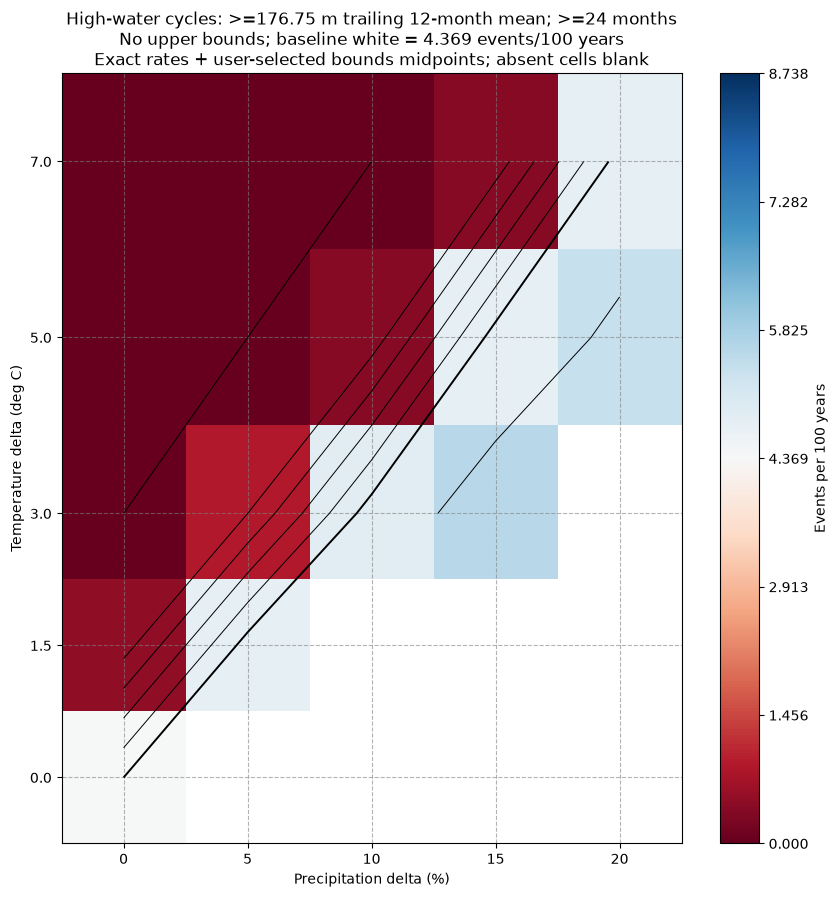

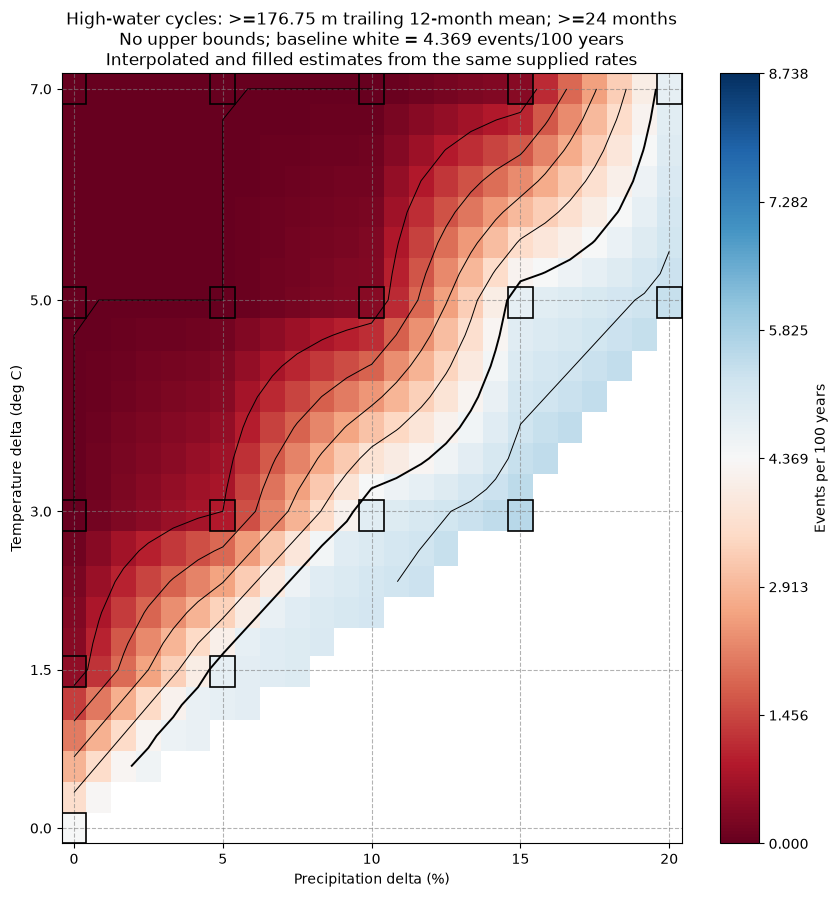

In [13]:
with pd.option_context('display.max_rows', None):
    display(plot_rates[rate_columns].round(3))
precipitation, temperature, grid = plot_grid_axes
display(pd.DataFrame(grid, index=temperature, columns=precipitation).round(3))
finite_points = np.argwhere(np.isfinite(grid))
if len(finite_points) < 3 or np.linalg.matrix_rank(finite_points[1:] - finite_points[0]) < 2:
    raise ValueError('Need three non-collinear supplied scenario rates.')
scale_half_range = max(1.0, float(np.max(np.abs(grid[np.isfinite(grid)] - baseline_plot_rate))))
scale_min = baseline_plot_rate - scale_half_range
scale_max = baseline_plot_rate + scale_half_range
surface_norm = Normalize(vmin=scale_min, vmax=scale_max)
color_ticks = np.linspace(scale_min, scale_max, 7).tolist()
contour_levels = tuple(np.linspace(scale_min, scale_max, 11))
assert np.isclose(surface_norm(baseline_plot_rate), 0.5)
assert np.isclose((scale_min + scale_max) / 2, baseline_plot_rate)
assert np.isclose(color_ticks[3], baseline_plot_rate)
assert np.isclose(contour_levels[5], baseline_plot_rate)
baseline_coordinates = parse_scenario_name('_0_0')
baseline_i = int(np.flatnonzero(temperature == baseline_coordinates[1])[0])
baseline_j = int(np.flatnonzero(precipitation == baseline_coordinates[0])[0])
assert np.isclose(grid[baseline_i, baseline_j], baseline_plot_rate)
title = (f'High-water cycles: >={PLOT_LOWER_M:.2f} m trailing 12-month mean; >=24 months\n'
         f'No upper bounds; baseline white = {baseline_plot_rate:.3f} events/100 years')
assert 'coverage' not in title.lower()
for interpolate, fillin, subtitle in [
    (False, False, 'Exact rates + user-selected bounds midpoints; absent cells blank'),
    (True, True, 'Interpolated and filled estimates from the same supplied rates'),
]:
    plot_response_surface(
        precipitation, temperature, grid.copy(), interpolate=interpolate, fillin=fillin,
        labels=('Precipitation delta (%)', 'Temperature delta (deg C)', 'Events per 100 years'),
        title=f'{title}\n{subtitle}', threshold=baseline_plot_rate, color_map_ticks=color_ticks,
        norm=surface_norm, levels=contour_levels,
        widths=tuple(1.4 if index == 5 else 0.7 for index in range(len(contour_levels))), show=True,
    )
    plt.close('all')

## Interpretation limits

Ordinary whole-parent classification is reproducible and does not multiply extreme physical spells into band fragments. Its thresholds remain conventional, with sensitivity disclosed; formal historical calibration and ecological validation require additional evidence. The notebook's standard band-only components retain ordinary library semantics for comparison.

The observed synthetic baseline does not independently validate 10-15-year historical cycling. Neither a descriptive event rate nor an average gap establishes recurrence probability, stationarity, independence, or a spectral period. Scenario event rates can rise or fall because levels shift into/out of the chosen high-state definition, spells merge, or extremes are screened; they are not ecological benefit scores.

Saved outputs are generated from these cells in order. Regression assertions deliberately flag changed baseline data/counts instead of silently preserving old numerical conclusions.